# Chapter 1 — Data Representation & Basic Statistics

## Introduction to Data Analysis and Machine Learning
### IFISC Master on Complex Systems

---

### What we cover

| # | Section | Slides |
|---|---------|--------|
| 0 | Setup: three real datasets and a network |
| 1 | Data types and encoding | *Not all data are numbers* |
| 2 | Choosing a representation | *Match the representation to the structure* |
| 3 | Empirical distributions | *From samples to distributions* |
| 4 | Describing distributions | *Compressing a distribution into a few numbers* |
| 5 | From variability to uncertainty | *A statistic computed from a sample is an estimator* |

### How to use it

- The slides give the concepts; here you **compute and plot every one of them** on real data.
- Run **every** code cell as we go: `Shift + Enter`.
- Exercises are marked **🔧 Your turn**. Solutions are hidden in collapsible blocks — try first, peek later.
- Exercises marked **🏠** are optional, for home.
- Nothing needs to be installed: this runs as-is in **Google Colab**.

---
# 0. Setup

Two new libraries on top of Chapter 0:

| Module | Alias | What it is for |
|--------|-------|----------------|
| `seaborn` | `sns` | statistical plots on top of matplotlib, plus example datasets |
| `networkx` | `nx` | graphs and networks |

The datasets are downloaded from the seaborn repository, so you need an internet connection.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import networkx as nx

rng = np.random.default_rng(seed=2026)            # one seeded generator for the whole notebook

penguins = sns.load_dataset("penguins").dropna()  # 3 penguin species, Antarctica (drops 11 incomplete rows)
diamonds = sns.load_dataset("diamonds")           # ~54 000 diamonds: carat, cut, price ...
flights  = sns.load_dataset("flights")            # monthly airline passengers, 1949-1960

print("penguins:", penguins.shape, "  diamonds:", diamonds.shape, "  flights:", flights.shape)
penguins.head()
diamonds.head()
# flights.head()


penguins: (333, 7)   diamonds: (53940, 10)   flights: (144, 3)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


---
# 1. Data types and encoding

## 1.1 Numerical, categorical, ordinal

pandas stores a type per column. `float64`/`int64` are numbers; `object`, `str` or `category` are labels.

In [18]:
penguins.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object

Same three families as in the slides, now with real data: a **numerical** variable (body mass), a **categorical** one (species: no order) and an **ordinal** one (diamond cut: Fair < Good < Very Good < Premium < Ideal).

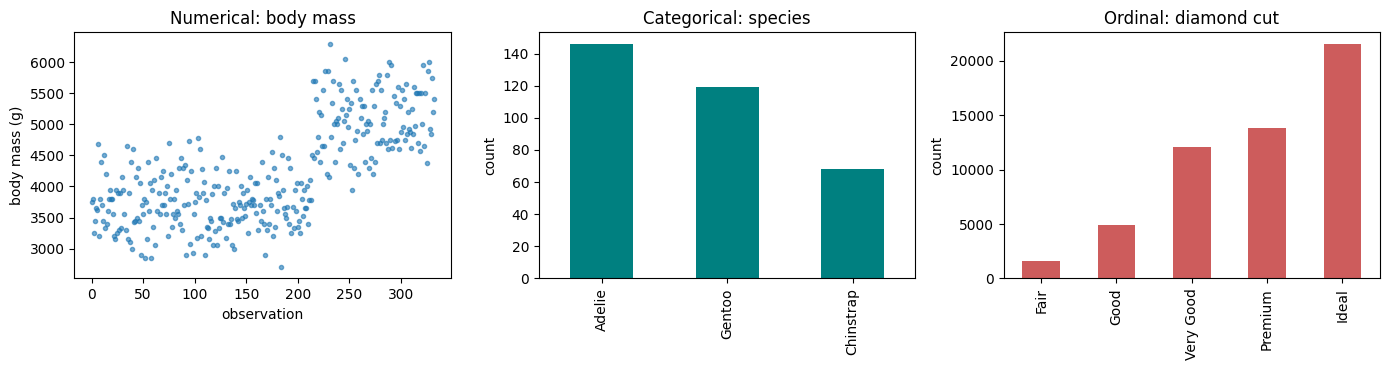

In [9]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]    # worst -> best

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].plot(penguins["body_mass_g"].values, ".", alpha=0.6)
axes[0].set(title="Numerical: body mass", xlabel="observation", ylabel="body mass (g)")

penguins["species"].value_counts().plot.bar(ax=axes[1], color="teal")
axes[1].set(title="Categorical: species", xlabel="", ylabel="count")

diamonds["cut"].value_counts().reindex(cut_order).plot.bar(ax=axes[2], color="indianred")
axes[2].set(title="Ordinal: diamond cut", xlabel="", ylabel="count")

plt.tight_layout()
plt.show()

> For categorical and ordinal data the natural plot is a **bar chart of counts** (`value_counts()`), not a histogram: there are no bins, only labels. For an ordinal variable, keep the bars in their natural order.

## 1.2 Label encoding: only when the order is meaningful

Algorithms need numbers. For an ordinal variable, replacing each level by its rank is fine, because the order is real:

In [10]:
cut = pd.Categorical(diamonds["cut"], categories=cut_order, ordered=True)
diamonds["cut_code"] = cut.codes                 # Fair -> 0, ..., Ideal -> 4

diamonds[["cut", "cut_code"]].drop_duplicates().sort_values("cut_code")

,cut,cut_code
8,Fair,0
2,Good,1
5,Very Good,2
1,Premium,3
0,Ideal,4


⚠️ Doing the same with `species` **invents** an order and a distance that do not exist:

In [2]:
species = ["Adelie", "Chinstrap", "Gentoo"]
label   = {s: i for i, s in enumerate(species)}   # Adelie 0, Chinstrap 1, Gentoo 2

print(label)
print("|Adelie - Chinstrap| =", abs(label["Adelie"] - label["Chinstrap"]))
print("|Adelie - Gentoo|    =", abs(label["Adelie"] - label["Gentoo"]), "  <- twice as far? Nothing in the data says so")

{'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
|Adelie - Chinstrap| = 1
|Adelie - Gentoo|    = 2   <- twice as far? Nothing in the data says so


## 1.3 One-hot encoding

One binary column per category. Every pair of categories ends up at the **same** distance, $\sqrt{2}$.

In [20]:
onehot = pd.get_dummies(penguins["species"], dtype=int)
print(onehot.drop_duplicates())                  # one row per species



     Adelie  Chinstrap  Gentoo
0         1          0       0
152       0          1       0
220       0          0       1


### 🔧 Your turn 1

Build a table ready for a model: the numerical columns `bill_length_mm` and `body_mass_g`, plus the one-hot encoding of `island` (use `prefix="island"` in `pd.get_dummies` and `pd.concat(..., axis=1)`). Print its shape and first rows.

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 1</b> (click to expand)</summary>

```python
X = pd.concat([penguins[["bill_length_mm", "body_mass_g"]],
               pd.get_dummies(penguins["island"], prefix="island", dtype=int)], axis=1)

print(X.shape)
X.head()
```

</details>

---
# 2. Choosing a representation

## 2.1 Different structures, different views

A point cloud → **scatter**. An ordered sequence → **time series**. Values on a grid → **heatmap**. The flights table is both a time series and a grid (month × year).

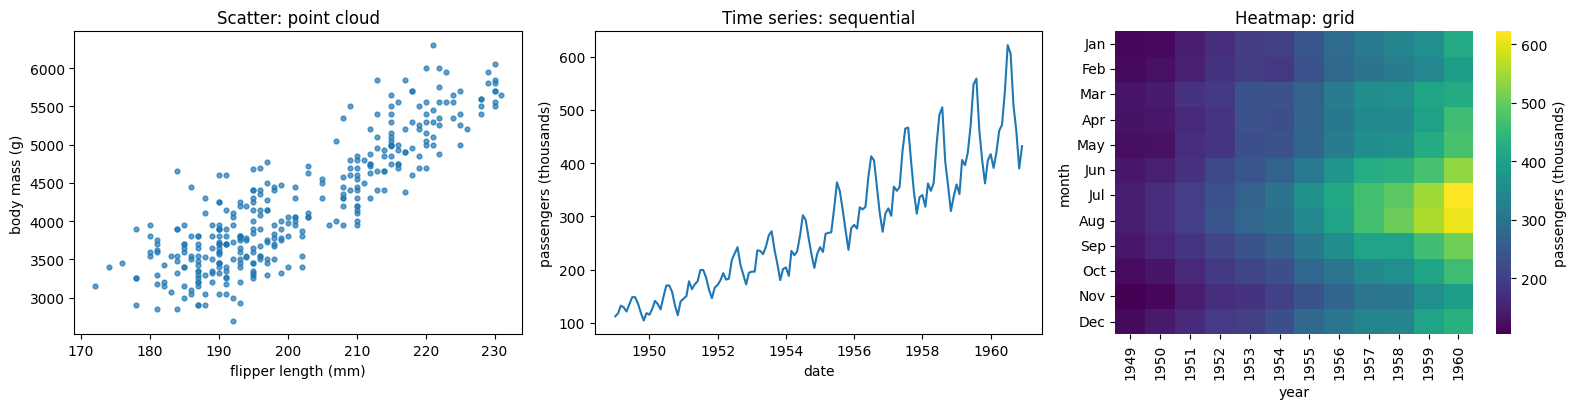

In [18]:
flights["date"] = pd.to_datetime(flights["year"].astype(str) + "-" + flights["month"].astype(str), format="%Y-%b")
grid = flights.pivot(index="month", columns="year", values="passengers")    # rows = month, columns = year

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].scatter(penguins["flipper_length_mm"], penguins["body_mass_g"], s=12, alpha=0.7)
axes[0].set(title="Scatter: point cloud", xlabel="flipper length (mm)", ylabel="body mass (g)")

axes[1].plot(flights["date"], flights["passengers"])
axes[1].set(title="Time series: sequential", xlabel="date", ylabel="passengers (thousands)")

sns.heatmap(grid, ax=axes[2], cmap="viridis", cbar_kws={"label": "passengers (thousands)"})
axes[2].set(title="Heatmap: grid")

plt.tight_layout()
plt.show()

> The heatmap shows at a glance two things that the time series mixes together: the **trend** (left → right) and the **seasonality** (July–August peak in every year).

## 2.2 Relational data: graph and adjacency matrix

For a network, the pairwise connections *are* the data. $A_{ij} = 1$ if nodes $i$ and $j$ are linked, $0$ otherwise.

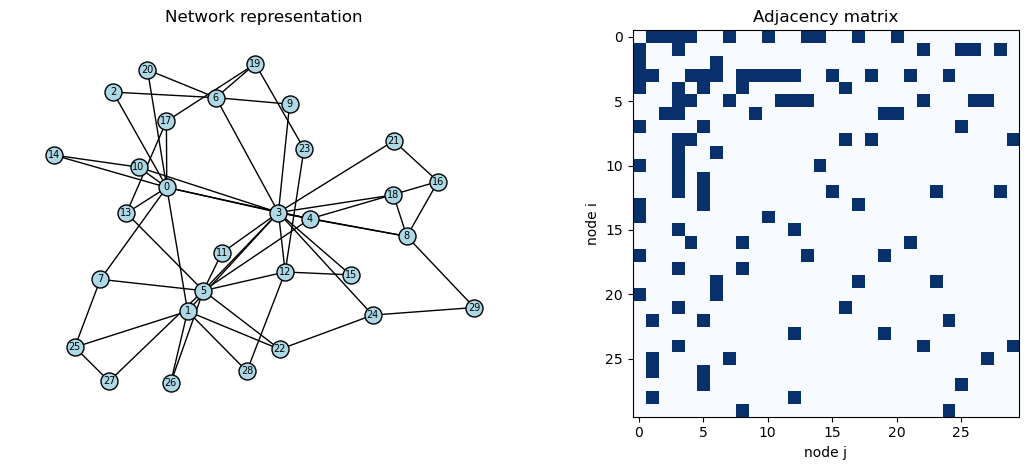

symmetric (undirected): True
degree of nodes 0-9    : [10.  6.  2. 14.  5.  9.  5.  3.  5.  2.]


In [3]:
G = nx.barabasi_albert_graph(n=30, m=2, seed=1)   # a small scale-free network
A = nx.to_numpy_array(G)                          # 30 x 30 adjacency matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

nx.draw(G, pos=nx.spring_layout(G, seed=1), ax=axes[0], node_size=150,
        node_color="lightblue", edgecolors="k", with_labels=True, font_size=7)
axes[0].set_title("Network representation")

axes[1].imshow(A, cmap="Blues")
axes[1].set(title="Adjacency matrix", xlabel="node j", ylabel="node i")

plt.tight_layout()
plt.show()

print("symmetric (undirected):", np.allclose(A, A.T))
print("degree of nodes 0-9    :", A.sum(axis=1)[:10])    # degree = row sum

## 2.3 The same data can reveal different structure

With 54 000 diamonds, a scatter plot saturates (**overplotting**): you see ink, not density. Density-based views count points per region instead.


*carat* is the mass of the diamond, in metric carats, the standard unit for gemstones: 1 ct = 200 mg = 0.2 g. In this dataset it ranges from 0.2 to 5.01 ct (0.04–1 g), and most diamonds are below 1 ct.

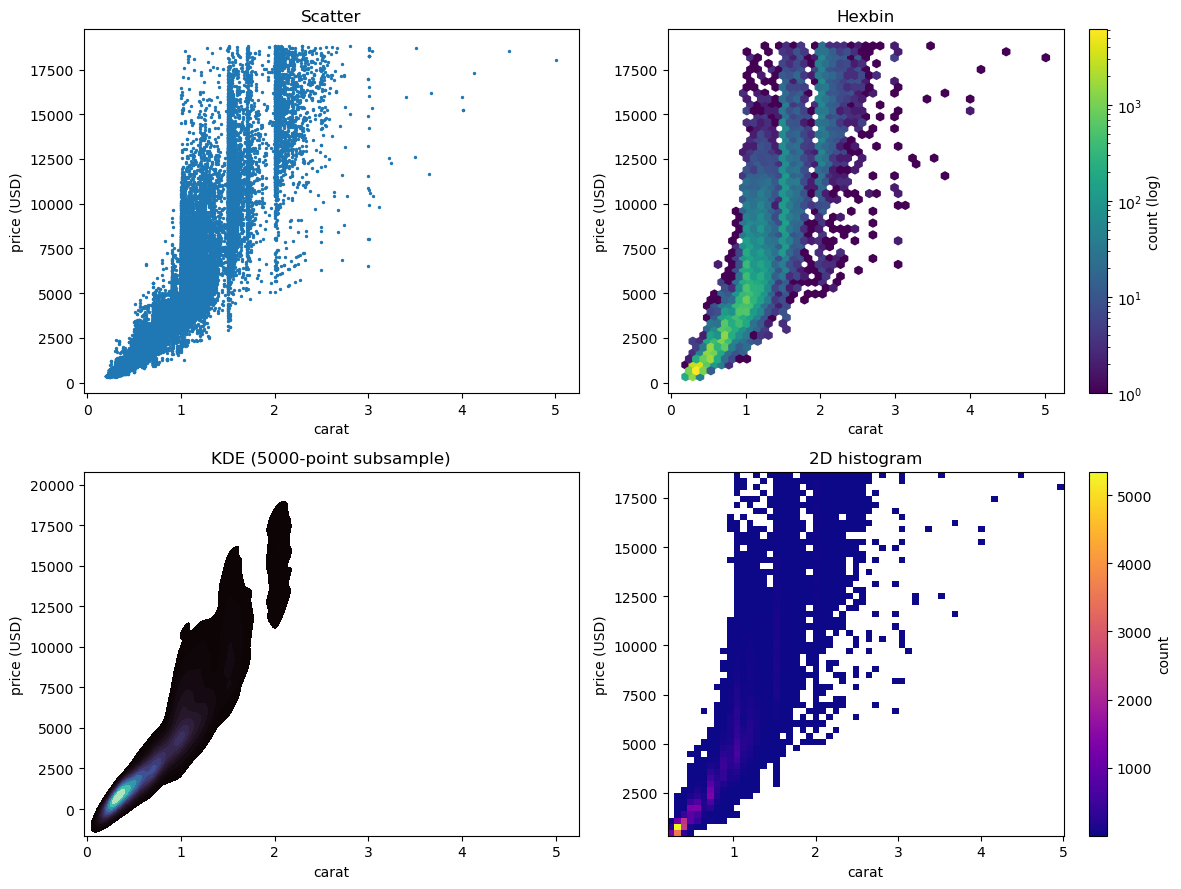

In [22]:
carat, price = diamonds["carat"], diamonds["price"]
sub = diamonds.sample(50000, random_state=0)       # KDE is slow on 54k points: a random subsample is enough

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].scatter(carat, price, s=2)
axes[0, 0].set_title("Scatter")

hb = axes[0, 1].hexbin(carat, price, gridsize=50, cmap="viridis", bins="log")
fig.colorbar(hb, ax=axes[0, 1], label="count (log)")
axes[0, 1].set_title("Hexbin")

sns.kdeplot(x=sub["carat"], y=sub["price"], fill=True, cmap="mako", levels=15, ax=axes[1, 0])
axes[1, 0].set_title("KDE (5000-point subsample)")

h = axes[1, 1].hist2d(carat, price, bins=60, cmap="plasma", cmin=1)
fig.colorbar(h[3], ax=axes[1, 1], label="count")
axes[1, 1].set_title("2D histogram")

for ax in axes.flat:
    ax.set_xlabel("carat")
    ax.set_ylabel("price (USD)")
plt.tight_layout()
plt.show()

> In the scatter, everything below ~1 carat is a solid blob of ink. The hexbin (log colour scale) shows that most diamonds are small and cheap, and that the vertical stripes at 1.0, 1.5 and 2.0 carat — diamonds are cut to "round" weights — are dense ridges, not just a few points.
>
> ⚠️ The KDE smooths beyond the data: it puts density at **negative** prices and carats. Smoothing is an assumption too.

---
# 3. Empirical distributions

## 3.1 Counts, relative frequencies, densities

A histogram = choose bins, count, optionally normalise. For $N$ observations and bin width $\Delta x$:

$$\text{relative frequency}_b = \frac{\text{count}_b}{N}, \qquad \text{density}_b = \frac{\text{count}_b}{N\,\Delta x}, \qquad \sum_b \text{density}_b\,\Delta x = 1$$

In [4]:
mass = penguins["body_mass_g"].values

counts, edges = np.histogram(mass, bins=15)       # counts per bin, and the 16 bin edges
width    = np.diff(edges)                         # bin widths (all equal here)
rel_freq = counts / len(mass)
density  = rel_freq / width

print(f"N = {len(mass)},  bin width = {width[0]:.1f} g")
print("sum of counts          :", counts.sum())
print("sum of rel. frequencies:", rel_freq.sum())
print("sum of density x width :", np.sum(density * width))
print("same as numpy density? :", np.allclose(density, np.histogram(mass, bins=15, density=True)[0]))

N = 333,  bin width = 240.0 g
sum of counts          : 333
sum of rel. frequencies: 1.0
sum of density x width : 1.0
same as numpy density? : True


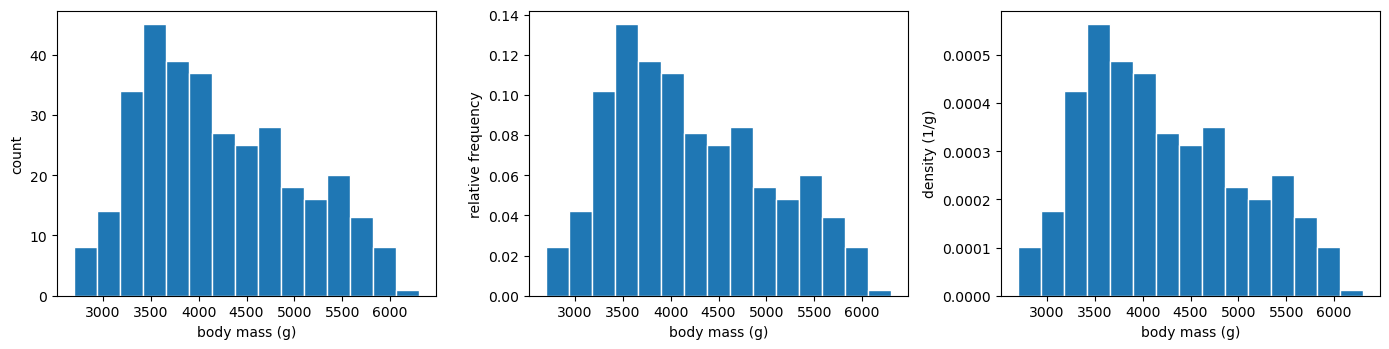

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

for ax, y, name in zip(axes, [counts, rel_freq, density], ["count", "relative frequency", "density (1/g)"]):
    ax.bar(edges[:-1], y, width=width, align="edge", edgecolor="white")
    ax.set(xlabel="body mass (g)", ylabel=name)

plt.tight_layout()
plt.show()

Same shape, three different y-axes. Only the **density** can be compared across samples of different size or different bin widths, and only the density can be overlaid on a theoretical PDF.

## 3.2 One distribution, different summaries

Histogram (full shape) → boxplot (quartiles + tails) → violin (smoothed density). Here, per species:

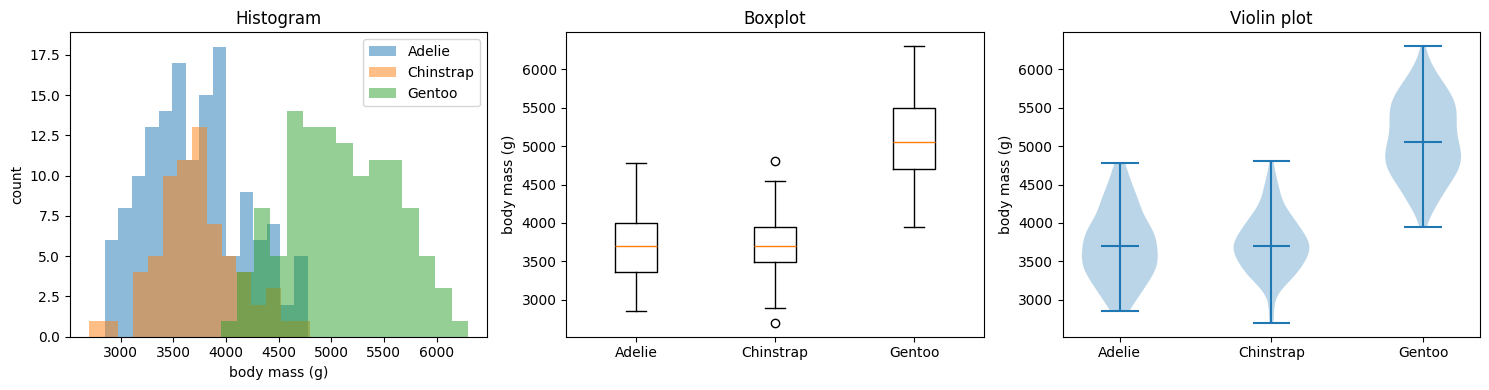

In [24]:
groups = [penguins.loc[penguins["species"] == s, "body_mass_g"] for s in species]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for g, s in zip(groups, species):
    axes[0].hist(g, bins=15, alpha=0.5, label=s)
axes[0].set(title="Histogram", xlabel="body mass (g)", ylabel="count")
axes[0].legend()

axes[1].boxplot(groups)
axes[1].set_title("Boxplot")

axes[2].violinplot(groups, showmedians=True)
axes[2].set_title("Violin plot")

for ax in axes[1:]:
    ax.set_xticks([1, 2, 3], species)
    ax.set_ylabel("body mass (g)")
plt.tight_layout()
plt.show()

## 3.3 Bin choice changes what you see

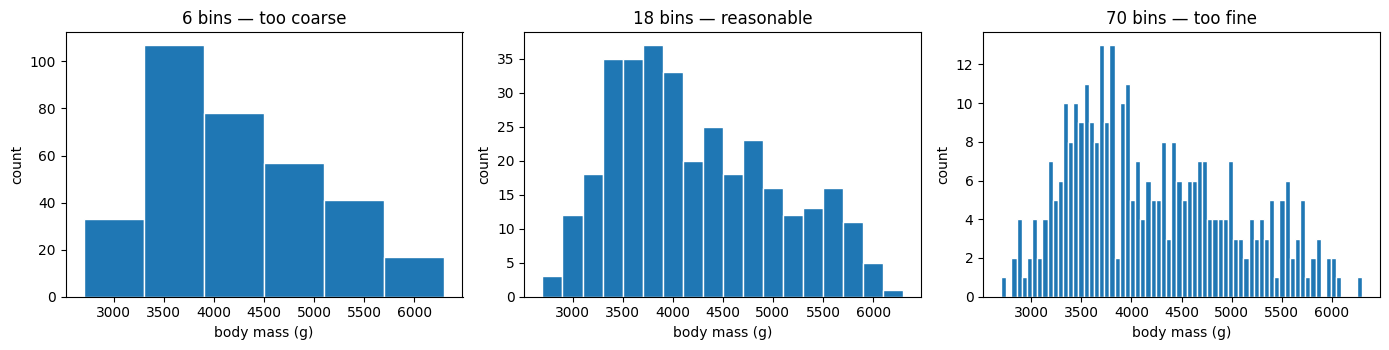

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

for ax, b, name in zip(axes, [6, 18, 70], ["too coarse", "reasonable", "too fine"]):
    ax.hist(mass, bins=b, edgecolor="white")
    ax.set(title=f"{b} bins — {name}", xlabel="body mass (g)", ylabel="count")

plt.tight_layout()
plt.show()

> With 6 bins the two groups (Adelie + Chinstrap vs Gentoo) merge; with 70 bins you see mostly noise. Rules of thumb exist (`bins="fd"`, Freedman–Diaconis) but the choice is **yours**, so try a few.

## 3.4 Linear or logarithmic bins?

Heavy-tailed data span orders of magnitude. The degree distribution of a Barabási–Albert network is the classic example: $P(k) \sim k^{-3}$.

min degree = 2,  median = 3,  max = 321


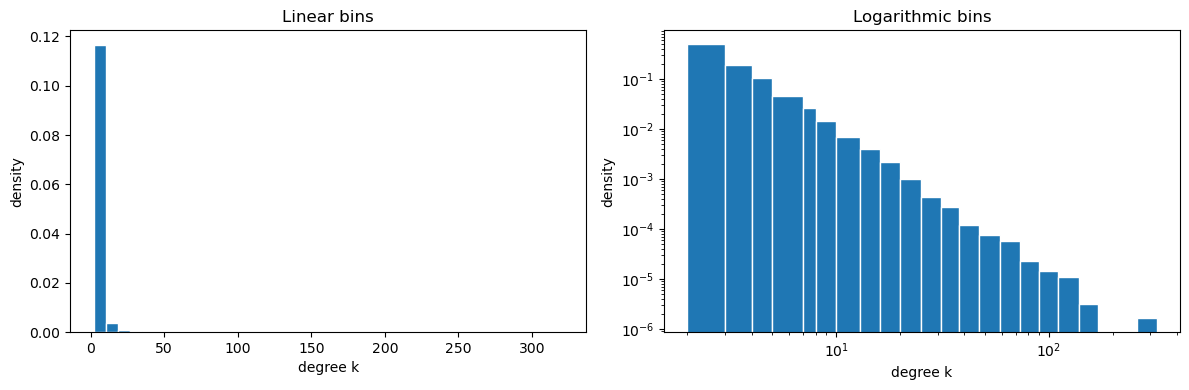

In [9]:
G_big = nx.barabasi_albert_graph(n=10_000, m=2, seed=0)
k = np.array([d for _, d in G_big.degree()])     # degree of every node

print(f"min degree = {k.min()},  median = {np.median(k):.0f},  max = {k.max()}")

lin_bins = np.linspace(k.min(), k.max(), 40)
log_bins = np.unique(np.logspace(np.log10(k.min()), np.log10(k.max() + 1), 25).astype(int))
# equal width in log k; rounded to integers because degrees are integers (otherwise some bins are empty)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(k, bins=lin_bins, density=True, edgecolor="white")
axes[0].set(title="Linear bins", xlabel="degree k", ylabel="density")

axes[1].hist(k, bins=log_bins, density=True, edgecolor="white")   # density=True divides by each bin's width
axes[1].set(title="Logarithmic bins", xlabel="degree k", ylabel="density", xscale="log", yscale="log")

plt.tight_layout()
plt.show()

> ⚠️ With log bins, **always** use `density=True`: bins at large $k$ are much wider and would collect more counts just because of their width. Try `density=False` in the cell above and watch the tail get artificially flatter.

## 3.5 ECDF and CCDF: distributions without bins

$$F(x) = P(X \le x), \qquad \text{CCDF}(x) = 1 - F(x) = P(X > x)$$

The empirical versions only need sorting and counting — no analyst choice.

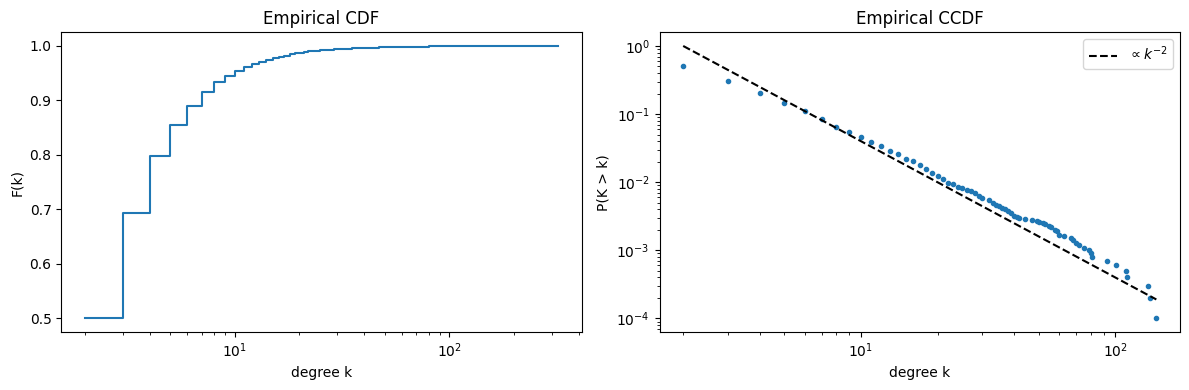

In [27]:
values, n_k = np.unique(k, return_counts=True)   # distinct degrees and how many nodes have each
F    = np.cumsum(n_k) / len(k)                   # ECDF:  P(K <= k)
ccdf = 1 - F                                     # CCDF:  P(K > k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].step(values, F, where="post")
axes[0].set(title="Empirical CDF", xlabel="degree k", ylabel="F(k)", xscale="log")

axes[1].loglog(values[:-1], ccdf[:-1], "o", ms=3)                       # last point is 0: not drawable on log axes
axes[1].loglog(values[:-1], (values[:-1] / 2.0) ** -2, "k--", label=r"$\propto k^{-2}$")
axes[1].set(title="Empirical CCDF", xlabel="degree k", ylabel="P(K > k)")
axes[1].legend()

plt.tight_layout()
plt.show()

> If $P(k) \sim k^{-\gamma}$, then $P(K>k) \sim k^{-(\gamma-1)}$: the CCDF of the BA network falls with slope $-2$. It is much less noisy than the histogram, because every point uses **all** the data above it.

### 🔧 Your turn 2

Plot the ECDF of `body_mass_g` for the three species in the same figure (sort each group, $F_i = i/N$). Draw a horizontal line at $F=0.5$ and read off each species' median. Check against `np.median`.

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 2</b> (click to expand)</summary>

```python
plt.figure(figsize=(7, 4))
for s in species:
    x = np.sort(penguins.loc[penguins["species"] == s, "body_mass_g"].values)
    F = np.arange(1, len(x) + 1) / len(x)
    plt.step(x, F, where="post", label=f"{s} (median = {np.median(x):.0f} g)")
plt.axhline(0.5, color="k", ls="--", lw=1)
plt.xlabel("body mass (g)")
plt.ylabel("F(x)")
plt.legend()
plt.show()
```

</details>

---
# 4. Describing distributions

## 4.1 Mean and standard deviation

$$\bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i, \qquad s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(x_i-\bar{x})^2, \qquad s = \sqrt{s^2}$$

Both carry the **units** of the data.

In [14]:
gentoo = penguins.loc[penguins["species"] == "Gentoo", "body_mass_g"].values
N = len(gentoo)

x_bar = np.sum(gentoo) / N                               # by hand
s     = np.sqrt(np.sum((gentoo - x_bar) ** 2) / (N - 1))

print(f"by hand : mean = {x_bar:.1f} g,  s = {s:.1f} g")
print(f"numpy   : mean = {np.mean(gentoo):.1f} g,  np.std = {np.std(gentoo):.1f} g   <- ddof=0 by default!")
print(f"numpy   : np.std(ddof=1) = {np.std(gentoo, ddof=1):.1f} g")
print(f"pandas  : .std() = {pd.Series(gentoo).std():.1f} g   <- ddof=1 by default")

by hand : mean = 5092.4 g,  s = 501.5 g
numpy   : mean = 5092.4 g,  np.std = 499.4 g   <- ddof=0 by default!
numpy   : np.std(ddof=1) = 501.5 g
pandas  : .std() = 501.5 g   <- ddof=1 by default


> ⚠️ `np.std` divides by $N$, pandas `.std()` by $N-1$. For large $N$ it barely matters; for small samples it does. Write `ddof=1` explicitly.

Use ddof=0 when your data are the whole population (or the true mean $\mu$ is known), and ddof=1 when they are a sample and you want to estimate the population variance: using $\bar{x}$ instead of $\mu$ makes the $1/N$ version systematically too small.

## 4.2 Mean and median answer different questions

The waiting-time example from the slides: 11 patients waited 8–22 min, one waited 180 min.

mean   = 28.3 min
median = 14.5 min


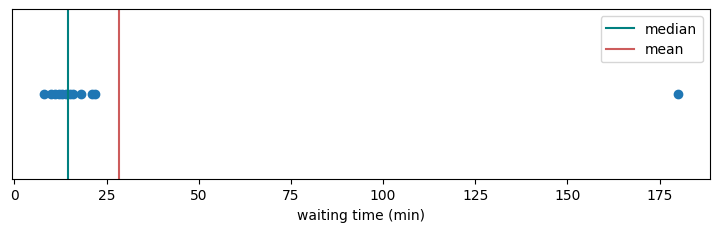

In [29]:
wait = np.array([8, 10, 11, 12, 13, 14, 15, 16, 18, 21, 22, 180])   # minutes

print(f"mean   = {wait.mean():.1f} min")
print(f"median = {np.median(wait):.1f} min")

plt.figure(figsize=(9, 2.2))
plt.plot(wait, np.zeros_like(wait), "o")
plt.axvline(np.median(wait), color="teal", label="median")
plt.axvline(wait.mean(), color="indianred", label="mean")
plt.yticks([])
plt.xlabel("waiting time (min)")
plt.legend()
plt.show()

## 4.3 Percentiles, quartiles, IQR and the boxplot

The $p$-th percentile is the value below which $p\,\%$ of the observations lie. $Q_1, Q_2, Q_3$ = 25th, 50th, 75th percentiles; $\text{IQR} = Q_3 - Q_1$. A boxplot draws the box from $Q_1$ to $Q_3$ and the whiskers up to the last observation inside $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$; anything beyond is drawn as an outlier.

Q1 = 190.0,  median = 197.0,  Q3 = 213.0,  IQR = 23.0 mm
fences: [155.5, 247.5] mm   ->  outliers: 0


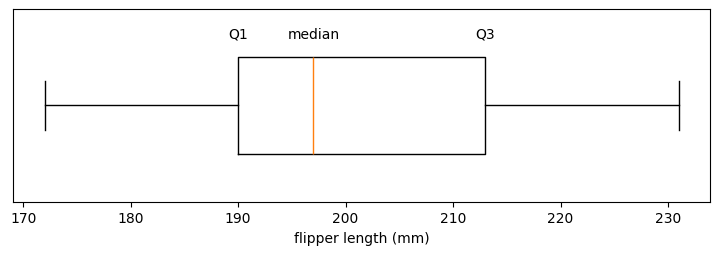

In [30]:
flipper = penguins["flipper_length_mm"].values

q1, q2, q3 = np.percentile(flipper, [25, 50, 75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Q1 = {q1},  median = {q2},  Q3 = {q3},  IQR = {iqr} mm")
print(f"fences: [{low}, {high}] mm   ->  outliers: {np.sum((flipper < low) | (flipper > high))}")

plt.figure(figsize=(9, 2.5))
plt.boxplot(flipper, vert=False, widths=0.5)
for v, name in zip([q1, q2, q3], ["Q1", "median", "Q3"]):
    plt.text(v, 1.35, name, ha="center")
plt.yticks([])
plt.xlabel("flipper length (mm)")
plt.show()

## 4.4 Spread: standard deviation or IQR?

Take a sample and add **one** extreme value. Which summaries move?

In [31]:
sample   = np.array([8.5, 10, 10.5, 10.5, 11, 12, 13, 13, 13, 13.5])
with_out = np.append(sample, 40)                 # the same sample + one outlier


def describe(x):
    q1, q3 = np.percentile(x, [25, 75])
    return {"mean": x.mean(), "SD": x.std(ddof=1), "median": np.median(x), "IQR": q3 - q1}


pd.DataFrame({"original": describe(sample), "+ outlier 40": describe(with_out)}).round(1)

,original,+ outlier 40
mean,11.5,14.1
SD,1.6,8.7
median,11.5,12.0
IQR,2.5,2.5


> Mean and SD react strongly; median and IQR barely move. They are **robust** summaries.

## 4.5 Everything at once with pandas

`describe()` gives count, mean, std (ddof=1), min, quartiles and max. With `groupby` you get it per group:

In [32]:
penguins.groupby("species")["body_mass_g"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,146.0,3706.2,458.6,2850.0,3362.5,3700.0,4000.0,4775.0
Chinstrap,68.0,3733.1,384.3,2700.0,3487.5,3700.0,3950.0,4800.0
Gentoo,119.0,5092.4,501.5,3950.0,4700.0,5050.0,5500.0,6300.0


### 🔧 Your turn 3

Write a function `summary(x)` that returns a dictionary with the mean, SD (`ddof=1`), median, IQR and the **number of outliers** by the $1.5\,\text{IQR}$ rule. Apply it to `diamonds["price"]`. Mean or median: which one describes a "typical" diamond better, and why?

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 3</b> (click to expand)</summary>

```python
def summary(x):
    x = np.asarray(x)
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    iqr = q3 - q1
    n_out = np.sum((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr))
    return {"mean": x.mean(), "SD": x.std(ddof=1), "median": med, "IQR": iqr, "n_outliers": n_out}


print({key: round(float(v), 1) for key, v in summary(diamonds["price"]).items()})
# mean ~ 3930 USD vs median ~ 2400 USD: the distribution is right-skewed (a few very expensive
# diamonds pull the mean up), so the median is the better "typical" price.
```

</details>

---
# 5. From variability to uncertainty

## 5.1 Data variability ≠ estimator uncertainty

The sample mean $\bar{x}$ is itself a random variable: another sample gives another $\bar{x}$. We can see its distribution — the **sampling distribution** — by simulation: draw many samples of size $n$ from the same skewed population.

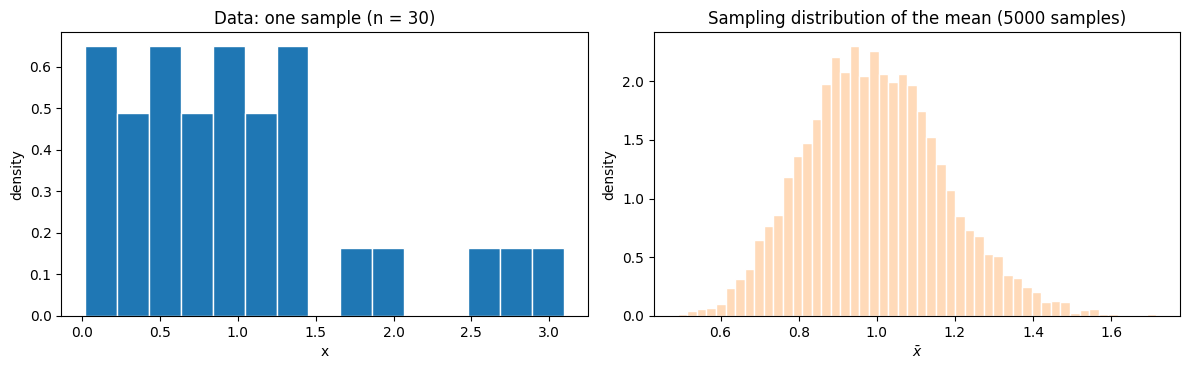

SD of the data      ~ 1.000
SD of the means     = 0.178
sigma / sqrt(n)     = 0.183   <- the standard error (SE)


In [33]:
n, n_rep = 30, 5000
samples = rng.exponential(scale=1.0, size=(n_rep, n))   # population: mean 1, SD 1, very skewed
means   = samples.mean(axis=1)                          # one mean per sample

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(samples[0], bins=15, density=True, edgecolor="white")
axes[0].set(title=f"Data: one sample (n = {n})", xlabel="x", ylabel="density")

axes[1].hist(means, bins=50, density=True, color="peachpuff", edgecolor="white")
axes[1].set(title=f"Sampling distribution of the mean ({n_rep} samples)", xlabel=r"$\bar{x}$", ylabel="density")

plt.tight_layout()
plt.show()

print(f"SD of the data      ~ {samples.std(ddof=1):.3f}")
print(f"SD of the means     = {means.std(ddof=1):.3f}")
print(f"sigma / sqrt(n)     = {1 / np.sqrt(n):.3f}   <- the standard error (SE)")

> The data are skewed; the sample means are almost Gaussian (central limit theorem) and much narrower: their spread is the **standard error**, $\text{SE} = s/\sqrt{n}$. SD answers *"how different are the observations?"*; SE answers *"how precise is my estimate of the mean?"*.

## 5.2 Bootstrap

In real life we have **one** sample. The bootstrap replaces "new samples from the population" by "resamples **with replacement** from our sample".

mean = 5092 g,  95% CI = [5004, 5182] g
bootstrap SD = 45.8 g   vs   s/sqrt(n) = 46.0 g


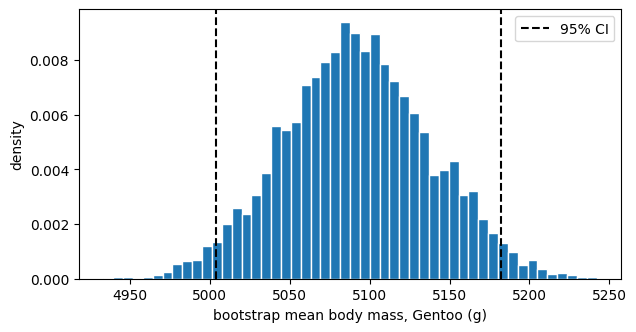

In [34]:
def bootstrap(x, stat=np.mean, n_boot=5000):
    """Return n_boot bootstrap replicates of stat(x)."""
    x = np.asarray(x)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))   # each row: one resample, with replacement
    return stat(x[idx], axis=1)                            # stat must accept 'axis' (np.mean, np.median, ...)


boot_means = bootstrap(gentoo)
ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])   # 95 % percentile interval

print(f"mean = {gentoo.mean():.0f} g,  95% CI = [{ci_low:.0f}, {ci_high:.0f}] g")
print(f"bootstrap SD = {boot_means.std(ddof=1):.1f} g   vs   s/sqrt(n) = {gentoo.std(ddof=1) / np.sqrt(len(gentoo)):.1f} g")

plt.figure(figsize=(7, 3.5))
plt.hist(boot_means, bins=50, density=True, edgecolor="white")
plt.axvline(ci_low, color="k", ls="--")
plt.axvline(ci_high, color="k", ls="--", label="95% CI")
plt.xlabel("bootstrap mean body mass, Gentoo (g)")
plt.ylabel("density")
plt.legend()
plt.show()

## 5.3 Error bars must say what they encode

Same data, same mean, three very different bars:

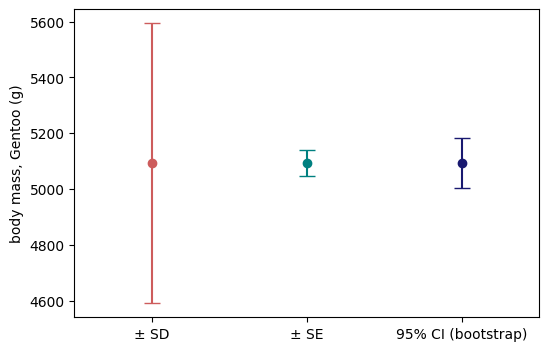

In [35]:
m  = gentoo.mean()
sd = gentoo.std(ddof=1)
se = sd / np.sqrt(len(gentoo))

plt.figure(figsize=(6, 4))
plt.errorbar(0, m, yerr=sd, fmt="o", capsize=6, color="indianred")
plt.errorbar(1, m, yerr=se, fmt="o", capsize=6, color="teal")
plt.errorbar(2, m, yerr=[[m - ci_low], [ci_high - m]], fmt="o", capsize=6, color="midnightblue")
plt.xticks([0, 1, 2], ["± SD", "± SE", "95% CI (bootstrap)"])
plt.xlim(-0.5, 2.5)
plt.ylabel("body mass, Gentoo (g)")
plt.show()

> A figure caption must say which one you drew. SD for the spread of the data, SE or CI for the precision of the estimate.

## 5.4 What does a 95 % confidence interval mean?

Simulate a population where we **know** the true mean (heights, $\mu = 172$ cm, $\sigma = 7$ cm), draw many samples, build $\bar{x} \pm 1.96\,\text{SE}$ for each, and count how many intervals contain $\mu$.

coverage over 10000 repetitions: 94.8%


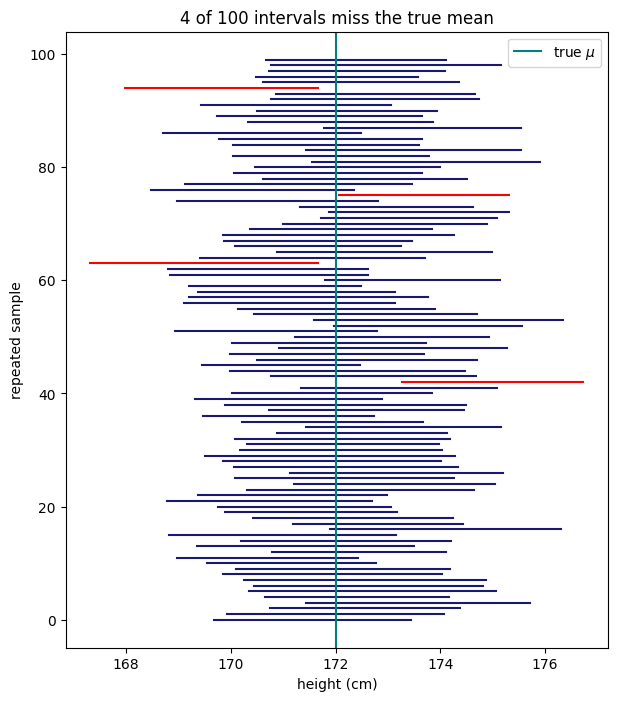

In [36]:
mu, sigma, n, n_rep = 172, 7, 50, 10_000

heights = rng.normal(mu, sigma, size=(n_rep, n))
x_bar   = heights.mean(axis=1)
se      = heights.std(axis=1, ddof=1) / np.sqrt(n)
low, high = x_bar - 1.96 * se, x_bar + 1.96 * se
hit = (low <= mu) & (mu <= high)                    # did this interval catch the true mean?

print(f"coverage over {n_rep} repetitions: {hit.mean():.1%}")

show = 100                                          # draw the first 100 intervals
plt.figure(figsize=(7, 8))
for i in range(show):
    plt.plot([low[i], high[i]], [i, i], color="midnightblue" if hit[i] else "red")
plt.axvline(mu, color="teal", label=r"true $\mu$")
plt.xlabel("height (cm)")
plt.ylabel("repeated sample")
plt.title(f"{np.sum(~hit[:show])} of {show} intervals miss the true mean")
plt.legend()
plt.show()

> The 95 % is a property of the **procedure**: about 95 of every 100 intervals built this way contain $\mu$. For one particular interval, $\mu$ is either inside or not — it is not "95 % probable".

### 🔧 Your turn 4

Using `bootstrap`, compute a 95 % CI for the **median** body mass of Gentoo penguins. Is it wider or narrower than the CI of the mean?

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 4</b> (click to expand)</summary>

```python
boot_medians = bootstrap(gentoo, stat=np.median)
lo, hi = np.percentile(boot_medians, [2.5, 97.5])

print(f"median = {np.median(gentoo):.0f} g,  95% CI = [{lo:.0f}, {hi:.0f}] g,  width = {hi - lo:.0f} g")
print(f"mean   = {gentoo.mean():.0f} g,  95% CI = [{ci_low:.0f}, {ci_high:.0f}] g,  width = {ci_high - ci_low:.0f} g")
# For near-Gaussian data the median is a less efficient estimator: its CI is wider.
```

</details>

---
# 🏠 Optional exercises

### 🏠 A. Linear vs logarithmic bins on real data

Plot the density histogram of `diamonds["price"]` with 50 linear bins and with 50 logarithmic bins (log x-axis). What does each representation show that the other hides?

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise A</b> (click to expand)</summary>

```python
price = diamonds["price"].values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(price, bins=50, density=True, edgecolor="white")
axes[0].set(title="Linear bins", xlabel="price (USD)", ylabel="density")

log_bins = np.logspace(np.log10(price.min()), np.log10(price.max()), 50)
axes[1].hist(price, bins=log_bins, density=True, edgecolor="white")
axes[1].set(title="Log bins", xlabel="price (USD)", ylabel="density", xscale="log")
plt.tight_layout()
plt.show()
# Log bins reveal two modes (~700 and ~4000 USD) that the linear view compresses into one decay.
```

</details>

### 🏠 B. Bootstrap for a difference

For Adelie penguins, estimate the difference in mean body mass male − female, with a 95 % bootstrap CI. Resample each sex **independently**. Does the interval contain 0?

In [ ]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise B</b> (click to expand)</summary>

```python
adelie = penguins[penguins["species"] == "Adelie"]
male   = adelie.loc[adelie["sex"] == "Male", "body_mass_g"].values
female = adelie.loc[adelie["sex"] == "Female", "body_mass_g"].values

diff_boot = bootstrap(male) - bootstrap(female)    # independent resamples of each group
lo, hi = np.percentile(diff_boot, [2.5, 97.5])

print(f"difference = {male.mean() - female.mean():.0f} g,  95% CI = [{lo:.0f}, {hi:.0f}] g")
# The interval is far from 0: males are heavier.
```

</details>

---
# Wrap-up

## Which tool for which question

| Question | Tool |
|----------|------|
| Is the variable a number, a label, or an ordered label? | `dtypes`, `value_counts()`; one-hot for labels, codes only for ordinal |
| What structure do the data have? | scatter · time series · heatmap · graph / adjacency matrix |
| Too many points to see? | hexbin, 2D histogram, KDE |
| What is the shape of the distribution? | density histogram (try several bins), ECDF |
| Does it span orders of magnitude? | log bins with `density=True`, CCDF on log-log axes |
| Where is the centre, how wide is it? | mean ± SD if roughly symmetric; median and IQR if skewed or with outliers |
| How precise is my estimate? | SE $= s/\sqrt{n}$, bootstrap CI |

## Traps you will actually meet

| Trap | Fix |
|------|-----|
| `np.std(x)` vs `series.std()` give different numbers | they use $N$ and $N-1$; write `ddof=1` |
| Histograms of samples of different size don't match | compare **densities**, not counts |
| Log-binned histogram with a strangely flat tail | you forgot `density=True` |
| Label-encoded categories used as numbers | one-hot unless the order is real |
| Error bars with no caption | say SD, SE or CI |
| "There is a 95 % probability that μ is in my interval" | no: 95 % of intervals built this way contain μ |

## Where to look things up

- NumPy statistics: <https://numpy.org/doc/stable/reference/routines.statistics.html>
- pandas `describe`, `groupby`: <https://pandas.pydata.org/docs/>
- seaborn gallery: <https://seaborn.pydata.org/examples/>
- NetworkX: <https://networkx.org/documentation/stable/>

---